# 14E — Uncapped text-seeded embedding portfolios

## Application

Can a human or LLM define an economic theme through a set of positive and negative seed firms, then let the holdings embedding expand those seeds into a diversified thematic portfolio without specifying a fixed number of securities?

The LLM supplies only the starting points and signs. Every non-seed firm with nonzero signed embedding support—meaning it cleared the previously frozen 95th-percentile random-pair similarity threshold—is admitted. Direct seeds remain in their assigned legs and override any conflicting neighbor sign. No top-*k* cap, return-based screening, or ex-post threshold adjustment is allowed.

Two portfolios are evaluated over the exact frozen three-month windows:

- **long-only:** all positive text seeds and positive embedding discoveries;
- **long–short:** the positive leg minus all negative text seeds and negative embedding discoveries.

SPY represents the broad equity benchmark. The equal-weight COPX/LIT/REMX basket is the critical-minerals equity-theme benchmark. Endpoint results use the experiment's original firm-level buy-and-hold convention; daily equal-weight paths are complementary diagnostics.

## 1. Setup and freeze the no-cap rule

In [ ]:
from pathlib import Path
import hashlib,json
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name!='sp500_critical_minerals':
 q=Path('/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals')
 if q.exists():ROOT=q
OUT=ROOT/'uncapped_seeded_embedding_v1';MAN=OUT/'manifests';FIG=OUT/'figures'
for q in [OUT,MAN,FIG]:q.mkdir(exist_ok=True)
RULE={'version':'uncapped_seeded_embedding_v1','direct_seed_sign':'sign(net_score); overrides embedding sign','nonseed_admission':'embedding_signed != 0, inherited from frozen q95 random-pair threshold','cap':None,'long_leg':'all positive direct seeds plus all positive supported nonseeds','short_leg':'all negative direct seeds plus all negative supported nonseeds','weighting':'equal weight within leg','primary_return':'cross-sectional mean of firm three-month buy-and-hold returns','path_return':'daily equal-weight diagnostic','benchmarks':['SPY market_return','equal-weight COPX/LIT/REMX broad_cm_equity_return'],'windows':'unchanged sp500_experiment_design_v1 forward months','no_outcome_based_selection':True}
rp=MAN/'portfolio_rule.json'
if rp.exists():assert json.loads(rp.read_text())==RULE
else:rp.write_text(json.dumps(RULE,indent=2,sort_keys=True)+'\n')
rh=hashlib.sha256(rp.read_bytes()).hexdigest();print({'rule_sha256':rh,'outcomes_opened':False})

{'rule_sha256': '51b1e62d3813d0f2655a9cc1443292f2ed22da20223210d1272ab3af7d3e083d', 'outcomes_opened': False}


## 2. Construct membership without opening returns

In [ ]:
signal_path=ROOT/'long_short_hybrid_v1/signed_signal_panel.parquet';null_path=ROOT/'embedding_propagation_v1/random_pair_null_summary.parquet';design_path=ROOT/'config/sp500_experiment_design_v1.json';daily_path=ROOT/'thematic_beta_v1/crsp_daily_firm_returns.parquet';factor_path=ROOT/'thematic_factor_v1/daily_critical_minerals_factors.parquet'
inputs=[signal_path,null_path,design_path,daily_path,factor_path];audit=pd.DataFrame([{'path':str(q),'exists':q.exists(),'sha256':hashlib.sha256(q.read_bytes()).hexdigest() if q.exists() else None} for q in inputs]);display(audit);assert audit.exists.all()
s=pd.read_parquet(signal_path);null=pd.read_parquet(null_path)[['vintage','q95']];rows=[]
for v,g in s.groupby('vintage'):
 direct=g.net_score.ne(0)
 for _,r in g.iterrows():
  if r.net_score>0:leg='long';source='direct_text_seed';sig=r.net_score
  elif r.net_score<0:leg='short';source='direct_text_seed';sig=r.net_score
  elif r.embedding_signed>0:leg='long';source='embedding_discovery';sig=r.embedding_signed
  elif r.embedding_signed<0:leg='short';source='embedding_discovery';sig=r.embedding_signed
  else:continue
  rows.append({'vintage':v,'permco':int(r.permco),'leg':leg,'source':source,'signal':sig})
m=pd.DataFrame(rows).drop_duplicates(['vintage','permco']);counts=m.groupby(['vintage','leg','source']).size().rename('firms').reset_index();tot=m.groupby(['vintage','leg']).size().rename('leg_firms').reset_index();m=m.merge(tot,on=['vintage','leg']);m['weight']=np.where(m.leg.eq('long'),1/m.leg_firms,-1/m.leg_firms);m=m.merge(null,on='vintage',validate='many_to_one');m.to_parquet(OUT/'frozen_uncapped_membership.parquet',index=False);display(counts);display(m.groupby(['vintage','leg']).agg(firms=('permco','nunique'),weight=('weight','sum')).reset_index());assert m.duplicated(['vintage','permco']).sum()==0

,path,exists,sha256
0,/Users/harmandeep/Desktop/Projects/Asset_Embed...,True,0ff8c58effb8f2813265bb45c307ee6d3dc42317327401...
1,/Users/harmandeep/Desktop/Projects/Asset_Embed...,True,7ac434ae702eef179154035242756678eb0552c9bf552f...
2,/Users/harmandeep/Desktop/Projects/Asset_Embed...,True,1c252e3f790722e8822ba9ef2a89b07d9aa14b3bb96e1f...
3,/Users/harmandeep/Desktop/Projects/Asset_Embed...,True,947695ca321f5efb2d0021161575155bc69bdc103b95c6...
4,/Users/harmandeep/Desktop/Projects/Asset_Embed...,True,25d1ddb36a98ae97a0f1340d23893e94dfae2fa68189e4...


,vintage,leg,source,firms
0,2024q1,long,direct_text_seed,14
1,2024q1,long,embedding_discovery,36
2,2024q1,short,direct_text_seed,41
3,2024q1,short,embedding_discovery,105
4,2024q2,long,direct_text_seed,15
5,2024q2,long,embedding_discovery,38
6,2024q2,short,direct_text_seed,39
7,2024q2,short,embedding_discovery,95
8,2024q3,long,direct_text_seed,15
9,2024q3,long,embedding_discovery,40


,vintage,leg,firms,weight
0,2024q1,long,50,1.0
1,2024q1,short,146,-1.0
2,2024q2,long,53,1.0
3,2024q2,short,134,-1.0
4,2024q3,long,55,1.0
5,2024q3,short,128,-1.0
6,2024q4,long,54,1.0
7,2024q4,short,130,-1.0


## 3. Open returns and create daily paths

Membership is already frozen. The long-only path uses the positive leg with weights summing to one. The long–short path uses both signed legs, with gross exposure two and net exposure zero.

In [ ]:
cfg=json.loads(design_path.read_text());w=pd.DataFrame([{'vintage':v['label'],'month':pd.Period(x,'M')} for v in cfg['vintages'] for x in v['forward_months']]);d=pd.read_parquet(daily_path);d['date']=pd.to_datetime(d.date);d['permco']=pd.to_numeric(d.permco,errors='coerce').astype('Int64');d['firm_return']=pd.to_numeric(d.firm_return,errors='coerce');d=d.dropna(subset=['permco','date','firm_return']).drop_duplicates(['permco','date']);dates=d[['date']].drop_duplicates();dates['month']=dates.date.dt.to_period('M');dates=dates.merge(w,on='month')
g=m.merge(dates,on='vintage').merge(d,on=['permco','date'],how='left',validate='many_to_one');g['observed_weight']=np.where(g.firm_return.notna(),g.weight.abs(),0);g['contribution']=g.weight*g.firm_return
leg=g.groupby(['vintage','date','leg'],as_index=False).agg(leg_return=('contribution','sum'),target_weight=('weight',lambda x:x.abs().sum()),observed_weight=('observed_weight','sum'),names=('firm_return','count'));leg['coverage']=leg.observed_weight/leg.target_weight
p=leg.pivot(index=['vintage','date'],columns='leg',values='leg_return').reset_index();p['long_only']=p['long'];p['long_short']=p['long']+p['short'];f=pd.read_parquet(factor_path);f['date']=pd.to_datetime(f.date);p=p.merge(f[['date','market_return','broad_cm_equity_return','broad_cm_equity_ex_market']],on='date',validate='many_to_one');p.to_parquet(OUT/'daily_portfolio_and_benchmark_returns.parquet',index=False)
coverage=leg.groupby(['vintage','leg']).agg(days=('date','nunique'),minimum_coverage=('coverage','min')).reset_index();display(coverage);assert coverage.minimum_coverage.min()>=.90

,vintage,leg,days,minimum_coverage
0,2024q1,long,63,1.000000
1,2024q1,short,63,0.986301
2,2024q2,long,63,0.981132
3,2024q2,short,63,1.000000
4,2024q3,long,60,1.000000
5,2024q3,short,60,1.000000
6,2024q4,long,62,1.000000
7,2024q4,short,62,0.992308


## 4. Original buy-and-hold endpoint comparison

Each firm's daily returns are compounded through its frozen window, and firm buy-and-hold returns are then equally averaged within each leg. This matches the original experiment more closely than daily rebalancing.

In [ ]:
firm_bhr=g.groupby(['vintage','leg','permco'],as_index=False).firm_return.agg(lambda x:(1+x.dropna()).prod()-1);legs=firm_bhr.groupby(['vintage','leg'],as_index=False).agg(firms=('permco','nunique'),buy_hold_return=('firm_return','mean'));wide=legs.pivot(index='vintage',columns='leg',values='buy_hold_return').reset_index();wide['embedding_long_only']=wide.long;wide['embedding_long_short']=wide.long-wide.short
bench=p.groupby('vintage',as_index=False).agg(sp500=('market_return',lambda x:(1+x).prod()-1),critical_minerals=('broad_cm_equity_return',lambda x:(1+x).prod()-1),critical_minerals_ex_market=('broad_cm_equity_ex_market',lambda x:(1+x).prod()-1));endpoint=wide.merge(bench,on='vintage');endpoint['long_only_minus_sp500']=endpoint.embedding_long_only-endpoint.sp500;endpoint['long_only_minus_minerals']=endpoint.embedding_long_only-endpoint.critical_minerals;endpoint['long_short_minus_cm_factor']=endpoint.embedding_long_short-endpoint.critical_minerals_ex_market;endpoint.to_parquet(OUT/'buy_hold_endpoint_results.parquet',index=False);display(endpoint.round(4));display(endpoint.drop(columns='vintage').agg(['mean','median']).round(4))

,vintage,long,short,embedding_long_only,embedding_long_short,sp500,critical_minerals,critical_minerals_ex_market,long_only_minus_sp500,long_only_minus_minerals,long_short_minus_cm_factor
0,2024q1,-0.0049,0.0660,-0.0049,-0.0710,0.0723,-0.1494,-0.2061,-0.0772,0.1445,0.1352
1,2024q2,0.0384,0.0590,0.0384,-0.0206,0.0722,0.1050,0.0304,-0.0338,-0.0666,-0.0510
2,2024q3,-0.0732,-0.0307,-0.0732,-0.0424,-0.0106,-0.0947,-0.0864,-0.0626,0.0215,0.0439
3,2024q4,0.0597,0.0660,0.0597,-0.0063,0.1078,0.0594,-0.0433,-0.0481,0.0003,0.0370


,long,short,embedding_long_only,embedding_long_short,sp500,critical_minerals,critical_minerals_ex_market,long_only_minus_sp500,long_only_minus_minerals,long_short_minus_cm_factor
mean,0.0050,0.0401,0.0050,-0.0351,0.0604,-0.0199,-0.0764,-0.0554,0.0249,0.0413
median,0.0167,0.0625,0.0167,-0.0315,0.0723,-0.0176,-0.0648,-0.0553,0.0109,0.0405


## 5. Daily risk, diversification, and benchmark statistics

In [ ]:
def stats(x):
 return pd.Series({'days':x.notna().sum(),'annualized_mean':252*x.mean(),'annualized_volatility':np.sqrt(252)*x.std(ddof=1),'annualized_sharpe':np.sqrt(252)*x.mean()/x.std(ddof=1) if x.std(ddof=1)>0 else np.nan,'cumulative_return':(1+x).prod()-1,'maximum_drawdown':((1+x).cumprod()/(1+x).cumprod().cummax()-1).min()})
long=p.groupby('date',as_index=False).agg(long_only=('long_only','mean'),long_short=('long_short','mean'),sp500=('market_return','first'),critical_minerals=('broad_cm_equity_return','first'),cm_factor=('broad_cm_equity_ex_market','first'));summary=pd.concat({q:stats(long[q]) for q in ['long_only','long_short','sp500','critical_minerals','cm_factor']},axis=1).T.reset_index(names='portfolio');summary.to_parquet(OUT/'calendar_time_performance_summary.parquet',index=False);display(summary.round(4))
div=m.groupby(['vintage','leg']).agg(firms=('permco','nunique'),effective_n=('weight',lambda x:1/np.square(x.abs()/x.abs().sum()).sum()),direct_seeds=('source',lambda x:int(x.eq('direct_text_seed').sum())),embedding_discoveries=('source',lambda x:int(x.eq('embedding_discovery').sum()))).reset_index();div.to_parquet(OUT/'diversification_summary.parquet',index=False);display(div.round(2))

,portfolio,days,annualized_mean,annualized_volatility,annualized_sharpe,cumulative_return,maximum_drawdown
0,long_only,248.0,0.0306,0.1973,0.1552,0.0112,-0.1960
1,long_short,248.0,-0.1478,0.0634,-2.3303,-0.1371,-0.1524
2,sp500,248.0,0.2544,0.1980,1.2852,0.2602,-0.1396
3,critical_minerals,248.0,-0.0536,0.3238,-0.1654,-0.0985,-0.3324
4,cm_factor,248.0,-0.3080,0.2567,-1.2000,-0.2851,-0.3125


,vintage,leg,firms,effective_n,direct_seeds,embedding_discoveries
0,2024q1,long,50,50.0,14,36
1,2024q1,short,146,146.0,41,105
2,2024q2,long,53,53.0,15,38
3,2024q2,short,134,134.0,39,95
4,2024q3,long,55,55.0,15,40
5,2024q3,short,128,128.0,38,90
6,2024q4,long,54,54.0,18,36
7,2024q4,short,130,130.0,38,92


## 6. Add the beta-neutral long–short weighting condition

The original portfolio is dollar-neutral: +100% long and −100% short. This additional specification is market-beta-neutral. It uses each firm's point-in-time 60-month beta at the vintage cutoff. Missing firm betas are replaced by the contemporaneous S&P 500 median so membership is not changed.

Starting from equal weights within each leg, let the average leg betas be \(eta_L\) and \(eta_S\). Gross sleeve exposures are

\[
W_L=
rac{2eta_S}{eta_L+eta_S},\qquad
W_S=
rac{2eta_L}{eta_L+eta_S}.
\]

Thus gross exposure remains 200%, while \(W_Leta_L-W_Seta_S=0\). Dollar net exposure is allowed to differ from zero.

In [ ]:
PROJECT=ROOT.parents[1];bc=[]
for q in range(1,5):
 z=pd.read_parquet(PROJECT/f'remaining_benchmarks/return_comovement/characteristics/2024q{q}.parquet')[['permco','beta_60m_paper']].copy();z['vintage']=f'2024q{q}';z['vintage_beta_median']=pd.to_numeric(z.beta_60m_paper,errors='coerce').median();bc.append(z)
bc=pd.concat(bc,ignore_index=True);vintage_medians=bc.groupby('vintage').beta_60m_paper.median();bn=m.drop(columns=['weight']).merge(bc.drop(columns='vintage_beta_median'),on=['vintage','permco'],how='left',validate='many_to_one');bn['vintage_beta_median']=bn.vintage.map(vintage_medians);bn['beta_raw']=pd.to_numeric(bn.beta_60m_paper,errors='coerce');bn['beta_imputed']=bn.beta_raw.isna();bn['beta_used']=bn.beta_raw.fillna(bn.vintage_beta_median);assert bn.beta_used.notna().all()
brows=[]
for v,z in bn.groupby('vintage'):
 bl=z.loc[z.leg.eq('long'),'beta_used'].mean();bs=z.loc[z.leg.eq('short'),'beta_used'].mean();assert bl>0 and bs>0
 wl=2*bs/(bl+bs);ws=2*bl/(bl+bs)
 for _,r in z.iterrows():
  nr=z.leg.eq(r.leg).sum();weight=(wl/nr if r.leg=='long' else -ws/nr);brows.append({**r.to_dict(),'weight':weight,'long_gross':wl,'short_gross':ws,'long_leg_beta':bl,'short_leg_beta':bs})
bn=pd.DataFrame(brows);bn.to_parquet(OUT/'frozen_beta_neutral_membership.parquet',index=False)
bdiag=bn.groupby('vintage').apply(lambda z:pd.Series({'firms':z.permco.nunique(),'imputed_betas':int(z.beta_imputed.sum()),'long_gross':z.loc[z.leg.eq('long'),'weight'].sum(),'short_gross':-z.loc[z.leg.eq('short'),'weight'].sum(),'net_dollar':z.weight.sum(),'gross':z.weight.abs().sum(),'estimated_portfolio_beta':np.dot(z.weight.to_numpy(float),z.beta_used.to_numpy(float))}),include_groups=False).reset_index();bdiag.to_parquet(OUT/'beta_neutral_weighting_diagnostics.parquet',index=False);display(bdiag.round(6))

,vintage,firms,imputed_betas,long_gross,short_gross,net_dollar,gross,estimated_portfolio_beta
0,2024q1,196.0,7.0,0.928996,1.071004,-0.142009,2.0,0.0
1,2024q2,187.0,8.0,0.908707,1.091293,-0.182586,2.0,0.0
2,2024q3,183.0,7.0,0.986347,1.013653,-0.027307,2.0,-0.0
3,2024q4,184.0,8.0,0.938484,1.061516,-0.123031,2.0,-0.0


## 7. Evaluate beta-neutral performance against the original portfolio and benchmarks

In [ ]:
bg=bn[['vintage','permco','weight']].merge(dates,on='vintage').merge(d,on=['permco','date'],how='left',validate='many_to_one');bg['contribution']=bg.weight*bg.firm_return;bd=bg.groupby(['vintage','date'],as_index=False).agg(beta_neutral_long_short=('contribution','sum'),observed_names=('firm_return','count'));p=p.merge(bd,on=['vintage','date'],validate='one_to_one')
bf=bg.groupby(['vintage','permco'],as_index=False).agg(weight=('weight','first'),firm_bhr=('firm_return',lambda x:(1+x.dropna()).prod()-1));be=bf.assign(contribution=lambda x:x.weight*x.firm_bhr).groupby('vintage',as_index=False).contribution.sum().rename(columns={'contribution':'beta_neutral_long_short'});endpoint=endpoint.merge(be,on='vintage',validate='one_to_one');endpoint.to_parquet(OUT/'buy_hold_endpoint_results.parquet',index=False);display(endpoint[['vintage','embedding_long_short','beta_neutral_long_short','sp500','critical_minerals_ex_market']].round(4))
bncal=p.groupby('date',as_index=False).agg(beta_neutral_long_short=('beta_neutral_long_short','mean'));long=long.merge(bncal,on='date',validate='one_to_one');summary=pd.concat({q:stats(long[q]) for q in ['long_only','long_short','beta_neutral_long_short','sp500','critical_minerals','cm_factor']},axis=1).T.reset_index(names='portfolio');summary.to_parquet(OUT/'calendar_time_performance_summary.parquet',index=False);display(summary.round(4))

,vintage,embedding_long_short,beta_neutral_long_short,sp500,critical_minerals_ex_market
0,2024q1,-0.0710,-0.0753,0.0723,-0.2061
1,2024q2,-0.0206,-0.0295,0.0722,0.0304
2,2024q3,-0.0424,-0.0410,-0.0106,-0.0864
3,2024q4,-0.0063,-0.0141,0.1078,-0.0433


,portfolio,days,annualized_mean,annualized_volatility,annualized_sharpe,cumulative_return,maximum_drawdown
0,long_only,248.0,0.0306,0.1973,0.1552,0.0112,-0.1960
1,long_short,248.0,-0.1478,0.0634,-2.3303,-0.1371,-0.1524
2,beta_neutral_long_short,248.0,-0.1689,0.0566,-2.9832,-0.1545,-0.1545
3,sp500,248.0,0.2544,0.1980,1.2852,0.2602,-0.1396
4,critical_minerals,248.0,-0.0536,0.3238,-0.1654,-0.0985,-0.3324
5,cm_factor,248.0,-0.3080,0.2567,-1.2000,-0.2851,-0.3125


## 8. Cumulative performance chart

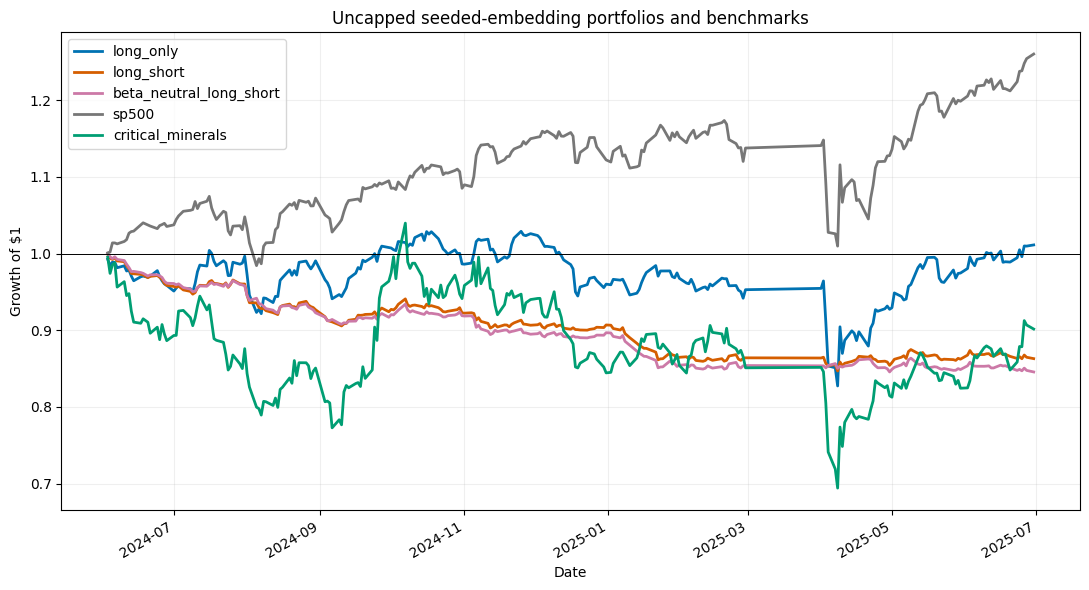

In [ ]:
wealth=long.set_index('date')[['long_only','long_short','beta_neutral_long_short','sp500','critical_minerals']].add(1).cumprod();ax=wealth.plot(figsize=(11,6),linewidth=2,color=['#0072B2','#D55E00','#CC79A7','#777777','#009E73']);ax.axhline(1,color='black',lw=.7);ax.set(title='Uncapped seeded-embedding portfolios and benchmarks',ylabel='Growth of $1',xlabel='Date');ax.grid(alpha=.2);plt.tight_layout();plt.savefig(FIG/'uncapped_portfolios_vs_benchmarks.png',dpi=180,bbox_inches='tight');plt.show()

## 9. Gates and reproducibility manifest

In [ ]:
gates=pd.DataFrame([{'gate':'four_vintages','value':m.vintage.nunique(),'threshold':4,'passed':m.vintage.nunique()==4},{'gate':'both_legs_every_vintage','value':m.groupby('vintage').leg.nunique().min(),'threshold':2,'passed':m.groupby('vintage').leg.nunique().min()==2},{'gate':'no_duplicate_firm_signs','value':m.duplicated(['vintage','permco']).sum(),'threshold':0,'passed':m.duplicated(['vintage','permco']).sum()==0},{'gate':'uncapped_embedding_discoveries','value':int((m.source=='embedding_discovery').sum()),'threshold':100,'passed':(m.source=='embedding_discovery').sum()>=100},{'gate':'minimum_return_coverage','value':coverage.minimum_coverage.min(),'threshold':.90,'passed':coverage.minimum_coverage.min()>=.90},{'gate':'beta_neutrality_tolerance','value':bdiag.estimated_portfolio_beta.abs().max(),'threshold':1e-10,'passed':bdiag.estimated_portfolio_beta.abs().max()<1e-10},{'gate':'beta_neutral_gross_200pct','value':bdiag.gross.min(),'threshold':2.0,'passed':np.allclose(bdiag.gross,2)}]);gates.to_parquet(MAN/'decision_gates.parquet',index=False);display(gates)
arts=[rp,OUT/'frozen_uncapped_membership.parquet',OUT/'frozen_beta_neutral_membership.parquet',OUT/'beta_neutral_weighting_diagnostics.parquet',OUT/'daily_portfolio_and_benchmark_returns.parquet',OUT/'buy_hold_endpoint_results.parquet',OUT/'calendar_time_performance_summary.parquet',OUT/'diversification_summary.parquet',FIG/'uncapped_portfolios_vs_benchmarks.png',MAN/'decision_gates.parquet'];pd.DataFrame([{'artifact':str(q.relative_to(ROOT)),'sha256':hashlib.sha256(q.read_bytes()).hexdigest()} for q in arts]).to_parquet(MAN/'artifact_inventory.parquet',index=False);(MAN/'manifest.json').write_text(json.dumps({'stage':RULE['version'],'rule_sha256':rh,'vintages':sorted(m.vintage.unique()),'all_gates_passed':bool(gates.passed.all()),'capped':False,'beta_neutral_robustness':True,'outcome_based_selection':False},indent=2,sort_keys=True)+'\n');print('Saved:',OUT)

,gate,value,threshold,passed
0,four_vintages,4.000000e+00,4.000000e+00,True
1,both_legs_every_vintage,2.000000e+00,2.000000e+00,True
2,no_duplicate_firm_signs,0.000000e+00,0.000000e+00,True
3,uncapped_embedding_discoveries,5.320000e+02,1.000000e+02,True
4,minimum_return_coverage,9.811321e-01,9.000000e-01,True
5,beta_neutrality_tolerance,3.469447e-16,1.000000e-10,True
6,beta_neutral_gross_200pct,2.000000e+00,2.000000e+00,True


Saved: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals/uncapped_seeded_embedding_v1


## Interpretation boundary

This test asks whether a text-seeded embedding expansion can produce a diversified portfolio with economically meaningful performance relative to broad-equity and thematic benchmarks. It does not establish causal exposure, and a short realized return window cannot establish long-run expected alpha. SPY and the ETF basket are comparison portfolios rather than perfect matched-risk counterfactuals. Results must therefore be read together with 14D factor attribution and the portfolio's realized risk and drawdown.